# Prediksi Penyakit Jantung dengan Supervised Learning

**Studi Kasus 4: Diagnosis Penyakit Jantung (Heart Disease UCI Dataset)**

Disusun oleh **Kelompok 6**, mata kuliah Machine Learning.

Notebook ini membangun model klasifikasi untuk membantu dokter mengenali pasien yang berisiko tinggi terkena penyakit jantung berdasarkan hasil pemeriksaan medis. Pengerjaan dibagi menjadi lima fase sesuai panduan tugas:

1. Fase 1: Clinical & Data Understanding
2. Fase 2: Data Preparation
3. Fase 3: Modeling (SVM, KNN, Logistic Regression)
4. Fase 4: Model Evaluation & Improvement
5. Fase 5: Clinical Insight & Deployment Concept

Notebook ini dijalankan dari folder `03-notebook`. Seluruh library yang dibutuhkan tercatat di `requirements.txt` pada root project.

## Fase 1: Clinical & Data Understanding

### 1.1 Clinical Understanding

**Masalah klinis.** Penyakit jantung koroner sering tidak bergejala jelas pada tahap awal, sehingga banyak pasien baru terdiagnosis ketika kondisinya sudah serius. Rumah sakit membutuhkan sistem pendukung keputusan klinis (*Clinical Decision Support System*) yang dapat menandai pasien berisiko tinggi dari data pemeriksaan rutin, seperti usia, tekanan darah, kolesterol, hasil EKG, dan hasil tes latihan jantung.

**Tujuan prediksi.** Model memprediksi kolom `target`: 1 berarti pasien diduga memiliki penyakit jantung, dan 0 berarti tidak. Hasil prediksi dipakai sebagai skrining awal untuk menentukan pasien mana yang perlu diperiksa lebih lanjut oleh dokter. Model tidak menggantikan diagnosis dokter.

**Metrik kesuksesan dari sudut pandang medis.** Ada dua jenis kesalahan prediksi:

- *False Negative* (FN): pasien yang sebenarnya sakit diprediksi sehat. Pasien ini bisa pulang tanpa penanganan, padahal risikonya fatal.
- *False Positive* (FP): pasien sehat diprediksi sakit. Akibatnya pasien menjalani pemeriksaan tambahan yang sebenarnya tidak perlu. Ini menambah biaya, waktu, dan kecemasan pasien. Beberapa pemeriksaan lanjutan, misalnya angiografi koroner, juga punya risiko sendiri, tetapi risikonya jauh lebih kecil dibanding pasien sakit yang terlewat.

Karena FN jauh lebih berbahaya, metrik utama proyek ini adalah **Recall kelas 1** (proporsi pasien sakit yang berhasil terdeteksi). Precision, F1-Score, dan ROC-AUC tetap dipantau supaya model tidak asal menebak semua pasien sebagai "sakit".

### 1.2 Persiapan Library dan Konstanta

Cell berikut memuat library, menetapkan `RANDOM_STATE = 42` agar hasil dapat direplikasi, dan menyiapkan fungsi `simpan_grafik` untuk menyimpan setiap grafik ke folder `05-output/figures`. Grafik yang tersimpan dipakai kembali di laporan dan slide. Fungsi `angka_id`, `persen_id`, dan `format_sumbu_id` dipakai agar angka pada grafik memakai koma desimal, sama seperti penulisan di laporan.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = Path("../02-dataset/heart_disease.csv")
FIG_DIR = Path("../05-output/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 20)


GRAFIK_TERSIMPAN = {}


def simpan_grafik(fig, nama: str) -> Path:
    """Simpan figure ke FIG_DIR/<nama>.png dan kembalikan path-nya."""
    path = FIG_DIR / f"{nama}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    GRAFIK_TERSIMPAN[nama] = fig
    return path


def angka_id(nilai: float, desimal: int = 2) -> str:
    """Format angka dengan koma desimal sesuai penulisan bahasa Indonesia, misalnya 54,3."""
    return f"{nilai:.{desimal}f}".replace(".", ",")


def persen_id(proporsi: float, desimal: int = 0) -> str:
    """Format proporsi (0 sampai 1) menjadi persen dengan koma desimal, misalnya 54,3%."""
    return angka_id(proporsi * 100, desimal) + "%"


def format_sumbu_id(sumbu, desimal: int = 2, persen: bool = False):
    """Ubah label angka pada sumbu matplotlib agar memakai koma desimal."""
    fungsi = (lambda x, _: persen_id(x, desimal)) if persen else (lambda x, _: angka_id(x, desimal))
    sumbu.set_major_formatter(FuncFormatter(fungsi))

### 1.3 Memuat Dataset

Dataset yang dipakai adalah Heart Disease UCI versi Kaggle. Variabel `df_raw` menyimpan data asli dan tidak pernah diubah. Semua proses pembersihan dilakukan pada salinannya.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Ukuran data: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Ukuran data: 303 baris x 14 kolom


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 1.4 Kamus Data

| Kolom | Arti medis | Tipe |
|---|---|---|
| `age` | Usia pasien (tahun) | Numerik |
| `sex` | Jenis kelamin (1 = laki-laki, 0 = perempuan) | Biner |
| `cp` | Tipe nyeri dada (0 = asymptomatic, 1 = atypical angina, 2 = non-anginal pain, 3 = typical angina) | Nominal |
| `trestbps` | Tekanan darah saat istirahat (mm Hg) | Numerik |
| `chol` | Kadar kolesterol serum (mg/dl) | Numerik |
| `fbs` | Gula darah puasa > 120 mg/dl (1 = ya, 0 = tidak) | Biner |
| `restecg` | Hasil EKG saat istirahat (0 = kemungkinan hipertrofi ventrikel kiri, 1 = normal, 2 = kelainan gelombang ST-T) | Nominal |
| `thalach` | Detak jantung maksimum saat tes latihan | Numerik |
| `exang` | Nyeri dada (angina) yang dipicu olahraga (1 = ya, 0 = tidak) | Biner |
| `oldpeak` | Depresi segmen ST saat latihan dibanding saat istirahat | Numerik |
| `slope` | Kemiringan segmen ST pada puncak latihan (0 = downsloping, 1 = flat, 2 = upsloping) | Nominal |
| `ca` | Jumlah pembuluh darah utama yang terlihat lewat fluoroskopi (0 sampai 3) | Ordinal |
| `thal` | Hasil tes thalium (1 = fixed defect, 2 = normal, 3 = reversible defect) | Nominal |
| `target` | Diagnosis (1 = ada penyakit jantung, 0 = tidak ada), **setelah dikoreksi** di bagian 1.8 | Target |

Arti kode `cp`, `restecg`, `slope`, `thal`, dan `target` di atas berbeda dengan dokumentasi yang beredar di halaman Kaggle. Kamus ini disusun dari hasil pencocokan dengan dataset UCI asli (lihat bagian 1.8).

### 1.5 Inspeksi Awal

`df.info()` menunjukkan tipe data dan jumlah nilai yang tidak kosong pada tiap kolom. `df.describe()` menampilkan statistik ringkas (rata-rata, sebaran, nilai minimum dan maksimum) untuk melihat apakah ada nilai yang janggal.

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.37,9.08,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.97,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.62,17.54,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.26,51.83,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.65,22.91,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


Semua kolom bertipe numerik dan tidak ada sel kosong. Namun, statistik di atas memperlihatkan nilai minimum `thal` = 0 dan nilai maksimum `ca` = 4. Kedua kode ini tidak ada dalam definisi kamus data, sehingga perlu diperiksa pada tahap berikutnya.

### Pengecekan otomatis: data berhasil dimuat
Cell `assert` ini memastikan dataset terbaca lengkap (303 baris, 14 kolom) dan folder grafik sudah tersedia. Kalau ada yang tidak sesuai, Run All akan berhenti di sini.

In [5]:
assert df_raw.shape == (303, 14)
assert list(df_raw.columns)[-1] == "target"
assert FIG_DIR.exists()
assert angka_id(54.321, 1) == "54,3" and persen_id(0.5432, 1) == "54,3%"
assert persen_id(0.27) == "27%"
print("Pengecekan data awal: OK")

Pengecekan data awal: OK


### 1.6 Pemeriksaan Kualitas Data: Missing Value dan Duplikat

Pembersihan selalu dimulai dari salinan `df_raw`, sehingga cell ini aman dijalankan berulang kali dan hasilnya tetap sama.

In [6]:
df = df_raw.copy()

print("Jumlah sel kosong per kolom:")
print(df.isna().sum().to_string())
print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")
df[df.duplicated(keep=False)]

Jumlah sel kosong per kolom:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0

Jumlah baris duplikat: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


Tidak ada sel kosong, tetapi ada **1 baris duplikat** (baris 163 dan 164 identik di semua kolom). Pada data medis, dua pasien dengan hasil pemeriksaan yang sama persis di 14 kolom hampir pasti merupakan data yang tercatat dua kali. Baris duplikat dihapus agar pasien tersebut tidak dihitung dua kali, terutama karena satu salinan bisa masuk ke data latih dan salinan lainnya ke data uji.

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Ukuran data setelah duplikat dihapus: {df.shape}")

Ukuran data setelah duplikat dihapus: (302, 14)


### 1.7 Missing Value Tersembunyi pada `thal` dan `ca`

Pada dataset UCI asli, `thal` hanya bernilai 1, 2, atau 3, dan `ca` hanya bernilai 0 sampai 3. Pada versi Kaggle ini muncul kode `thal = 0` dan `ca = 4`, yang di dataset asli merupakan data yang hilang (tercatat sebagai `?`). Artinya, data ini sebenarnya punya missing value, hanya saja ditulis sebagai angka.

Kode tersebut diubah menjadi `NaN` supaya tidak dianggap sebagai kategori medis yang sah.

In [8]:
# Jumlah dihitung dari data mentah (tanpa duplikat) supaya output tetap sama walaupun cell dijalankan ulang
sebelum = df_raw.drop_duplicates()
print("Sebelum diubah:")
print(f"  thal = 0 : {(sebelum['thal'] == 0).sum()} baris")
print(f"  ca   = 4 : {(sebelum['ca'] == 4).sum()} baris")

df["thal"] = df["thal"].replace(0, np.nan)
df["ca"] = df["ca"].replace(4, np.nan)

print("\nMissing value setelah diubah:")
print(df[["thal", "ca"]].isna().sum().to_string())

Sebelum diubah:
  thal = 0 : 2 baris
  ca   = 4 : 4 baris

Missing value setelah diubah:
thal    2
ca      4


Jumlah baris yang terdampak kecil (2 baris pada `thal` dan 4 baris pada `ca`), sehingga baris tersebut tidak dibuang. Nilai yang hilang akan diisi dengan **modus** (nilai yang paling sering muncul) pada Fase 2. Pengisian sengaja dilakukan di dalam pipeline setelah *train-test split*, supaya modus dihitung hanya dari data latih dan tidak terjadi *data leakage* (informasi data uji bocor ke proses training).

### 1.8 Koreksi Label `target` dan Kamus Data

Saat eksplorasi awal, pola data terlihat berkebalikan dengan pengetahuan medis. Kelompok `target = 1` (yang menurut dokumentasi Kaggle berarti sakit jantung) justru memiliki detak jantung maksimum lebih tinggi, depresi ST lebih rendah, dan lebih jarang mengalami angina saat olahraga. Untuk memastikannya, dataset ini dicocokkan dengan sumber aslinya, yaitu file `processed.cleveland.data` dari UCI Machine Learning Repository. Salinan file tersebut disimpan di `02-dataset/uci-cleveland-asli.data`.

Setiap pasien dicocokkan berdasarkan lima kolom numerik yang hampir unik untuk tiap orang: `age`, `trestbps`, `chol`, `thalach`, dan `oldpeak`. Pada data UCI asli, kolom diagnosis bernama `num` (0 = tidak ada penyakit jantung, 1 sampai 4 = ada penyakit jantung dengan tingkat keparahan berbeda), sedangkan missing value ditulis sebagai `?`.

In [9]:
UCI_PATH = Path("../02-dataset/uci-cleveland-asli.data")
KOLOM_UCI = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
             "exang", "oldpeak", "slope", "ca", "thal", "num"]
KUNCI_COCOK = ["age", "trestbps", "chol", "thalach", "oldpeak"]

uci = pd.read_csv(UCI_PATH, header=None, names=KOLOM_UCI, na_values="?")
cocok = df_raw.reset_index().merge(uci, on=KUNCI_COCOK, suffixes=("_kaggle", "_uci"))
print(f"Baris Kaggle: {len(df_raw)}, baris UCI: {len(uci)}, pasangan yang cocok: {len(cocok)}")
print(f"Setiap baris Kaggle cocok dengan tepat satu baris UCI: {cocok['index'].is_unique and len(cocok) == len(df_raw)}")

pd.crosstab(
    cocok["target"].map({0: "target = 0", 1: "target = 1"}).rename("Label Kaggle"),
    (cocok["num"] > 0).map({False: "Sehat (num = 0)", True: "Sakit (num > 0)"}).rename("Diagnosis asli UCI"),
)

Baris Kaggle: 303, baris UCI: 303, pasangan yang cocok: 303
Setiap baris Kaggle cocok dengan tepat satu baris UCI: True


Diagnosis asli UCI,Sakit (num > 0),Sehat (num = 0)
Label Kaggle,,
target = 0,138,0
target = 1,0,165


Hasilnya tegas. Seluruh 303 pasien cocok satu-satu, dan **semua** pasien berlabel `target = 1` pada versi Kaggle ternyata tercatat **sehat** di data asli, sedangkan semua pasien berlabel `target = 0` tercatat **sakit**. Jadi label `target` pada versi Kaggle terbalik 100%.

Pencocokan yang sama juga dipakai untuk memeriksa arti kode kolom kategorikal:

In [10]:
print("Kode cp Kaggle -> kode cp UCI asli (1 = typical, 2 = atypical, 3 = non-anginal, 4 = asymptomatic)")
print(pd.crosstab(cocok["cp_kaggle"], cocok["cp_uci"]), "\n")
print("Kode thal Kaggle -> kode thal UCI asli (3 = normal, 6 = fixed defect, 7 = reversible defect, NaN = hilang)")
print(pd.crosstab(cocok["thal_kaggle"], cocok["thal_uci"].fillna(-1).replace(-1, "NaN")), "\n")
print("Kode ca Kaggle -> kode ca UCI asli")
print(pd.crosstab(cocok["ca_kaggle"], cocok["ca_uci"].fillna(-1).replace(-1, "NaN")), "\n")
print("Kode restecg Kaggle -> kode restecg UCI asli (0 = normal, 1 = kelainan ST-T, 2 = hipertrofi ventrikel kiri)")
print(pd.crosstab(cocok["restecg_kaggle"], cocok["restecg_uci"]), "\n")
print("Kode slope Kaggle -> kode slope UCI asli (1 = upsloping, 2 = flat, 3 = downsloping)")
print(pd.crosstab(cocok["slope_kaggle"], cocok["slope_uci"]))

Kode cp Kaggle -> kode cp UCI asli (1 = typical, 2 = atypical, 3 = non-anginal, 4 = asymptomatic)
cp_uci     1.0  2.0  3.0  4.0
cp_kaggle                    
0            0    0    0  143
1            0   50    0    0
2            0    0   87    0
3           23    0    0    0 

Kode thal Kaggle -> kode thal UCI asli (3 = normal, 6 = fixed defect, 7 = reversible defect, NaN = hilang)
thal_uci     3.0  6.0  7.0  NaN
thal_kaggle                    
0              0    0    0    2
1              0   18    0    0
2            166    0    0    0
3              0    0  117    0 

Kode ca Kaggle -> kode ca UCI asli
ca_uci     0.0  1.0  2.0  3.0  NaN
ca_kaggle                         
0          175    0    0    0    0
1            0   65    0    0    0
2            0    0   38    0    0
3            0    0    0   20    0
4            0    0    0    0    5 

Kode restecg Kaggle -> kode restecg UCI asli (0 = normal, 1 = kelainan ST-T, 2 = hipertrofi ventrikel kiri)
restecg_uci     0.0  1.0  2.0

Temuan dari pencocokan:

- `cp`: kode 0 pada versi Kaggle berarti *asymptomatic* dan kode 3 berarti *typical angina*. Urutannya terbalik dibanding dokumentasi Kaggle. Kamus data di bagian 1.4 sudah memakai arti yang benar.
- `thal`: kode 1 berarti *fixed defect* dan kode 2 berarti *normal*. Kamus data di bagian 1.4 juga sudah disesuaikan.
- `restecg`: kode 0 berarti kemungkinan hipertrofi ventrikel kiri, kode 1 berarti normal, dan kode 2 berarti kelainan gelombang ST-T.
- `slope`: urutannya terbalik dibanding data asli. Kode 0 berarti *downsloping*, kode 1 berarti *flat*, dan kode 2 berarti *upsloping*.
- `thal = 0` dan `ca = 4` memang berasal dari data yang hilang (`?`) di dataset asli. Ini membuktikan keputusan di bagian 1.7 sudah tepat.

**Keputusan:** label dibalik dengan `target = 1 - target`, sehingga `1` benar-benar berarti ada penyakit jantung, sesuai definisi di panduan tugas. File dataset asli tidak diubah. Koreksi dilakukan di notebook agar setiap perubahan dapat ditelusuri.

In [11]:
# Label dihitung dari df_raw supaya cell ini aman dijalankan ulang (label tidak terbalik dua kali)
target_kaggle = df_raw.drop_duplicates()["target"].to_numpy()
df["target"] = 1 - target_kaggle

print("Jumlah pasien per kelas setelah koreksi:")
print(df["target"].map({0: "Sehat (0)", 1: "Sakit Jantung (1)"}).value_counts().to_string())

Jumlah pasien per kelas setelah koreksi:
target
Sehat (0)            164
Sakit Jantung (1)    138


### Pengecekan otomatis: hasil pembersihan data
Memastikan duplikat sudah hilang, kode `thal=0` dan `ca=4` sudah menjadi NaN, label `target` sudah dikoreksi, dan `df_raw` tetap utuh.

In [12]:
# Bukti koreksi: ke-303 baris cocok satu-satu dengan data UCI asli
assert len(cocok) == 303 and cocok["index"].is_unique
assert ((1 - cocok["target"]) == (cocok["num"] > 0).astype(int)).all()
assert cocok.groupby("cp_kaggle")["cp_uci"].unique().map(list).to_dict() == {0: [4.0], 1: [2.0], 2: [3.0], 3: [1.0]}
assert cocok.groupby("thal_kaggle")["thal_uci"].unique().map(list).to_dict()[1] == [6.0]
assert cocok.groupby("thal_kaggle")["thal_uci"].unique().map(list).to_dict()[2] == [3.0]
assert cocok.groupby("thal_kaggle")["thal_uci"].unique().map(list).to_dict()[3] == [7.0]
peta = lambda k: cocok.groupby(f"{k}_kaggle")[f"{k}_uci"].unique().map(list).to_dict()
assert peta("restecg") == {0: [2.0], 1: [0.0], 2: [1.0]}
assert peta("slope") == {0: [3.0], 1: [2.0], 2: [1.0]}

# Hasil pembersihan
assert df.shape == (302, 14)
assert df.duplicated().sum() == 0
assert df["thal"].isna().sum() == 2
assert df["ca"].isna().sum() == 4  # 1 dari 5 baris ca=4 ikut terhapus sebagai duplikat
assert (df["thal"] == 0).sum() == 0 and (df["ca"] == 4).sum() == 0
assert df["target"].value_counts().to_dict() == {0: 164, 1: 138}  # 1 = sakit jantung (setelah koreksi)
assert (df_raw["target"] == 1).sum() == 165  # df_raw tidak ikut berubah
print("Pengecekan pembersihan data: OK")

Pengecekan pembersihan data: OK


### 1.9 Exploratory Data Analysis (EDA)

Semua grafik di bawah memakai data yang sudah dibersihkan dan labelnya sudah dikoreksi (`df`, 302 pasien). Label kelas ditulis "Sehat (0)" dan "Sakit Jantung (1)" sesuai definisi `target` di panduan tugas.

In [13]:
LABEL_TARGET = {0: "Sehat (0)", 1: "Sakit Jantung (1)"}
WARNA_TARGET = {"Sehat (0)": "#4C9F70", "Sakit Jantung (1)": "#C44E52"}
LABEL_CP = {
    0: "Asymptomatic (0)",
    1: "Atypical angina (1)",
    2: "Non-anginal pain (2)",
    3: "Typical angina (3)",
}

df_eda = df.assign(
    diagnosis=df["target"].map(LABEL_TARGET),
    tipe_nyeri=df["cp"].map(LABEL_CP),
)

#### a. Distribusi kelas `target`

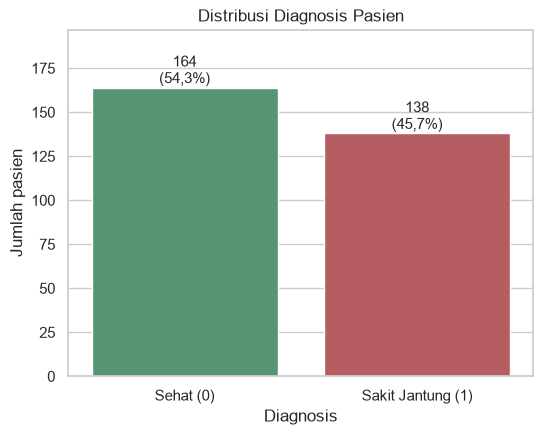

In [14]:
fig, ax = plt.subplots(figsize=(6, 4.5))
urutan = list(LABEL_TARGET.values())
sns.countplot(data=df_eda, x="diagnosis", order=urutan, hue="diagnosis",
              palette=WARNA_TARGET, legend=False, ax=ax)
total = len(df_eda)
for bar in ax.patches:
    jumlah = int(bar.get_height())
    ax.annotate(f"{jumlah}\n({persen_id(jumlah / total, 1)})",
                (bar.get_x() + bar.get_width() / 2, jumlah),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Distribusi Diagnosis Pasien")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Jumlah pasien")
ax.set_ylim(0, df_eda["diagnosis"].value_counts().max() * 1.2)
simpan_grafik(fig, "fase-1-distribusi-target")
plt.show()

**Temuan:** Terdapat 138 pasien sakit jantung (45,7%) dan 164 pasien sehat (54,3%). Proporsi kedua kelas cukup seimbang, sehingga tidak perlu teknik penyeimbangan data seperti SMOTE. Walaupun begitu, *train-test split* tetap memakai `stratify=y` agar proporsi ini sama di data latih dan data uji.

#### b. Tipe nyeri dada (`cp`) terhadap `target`

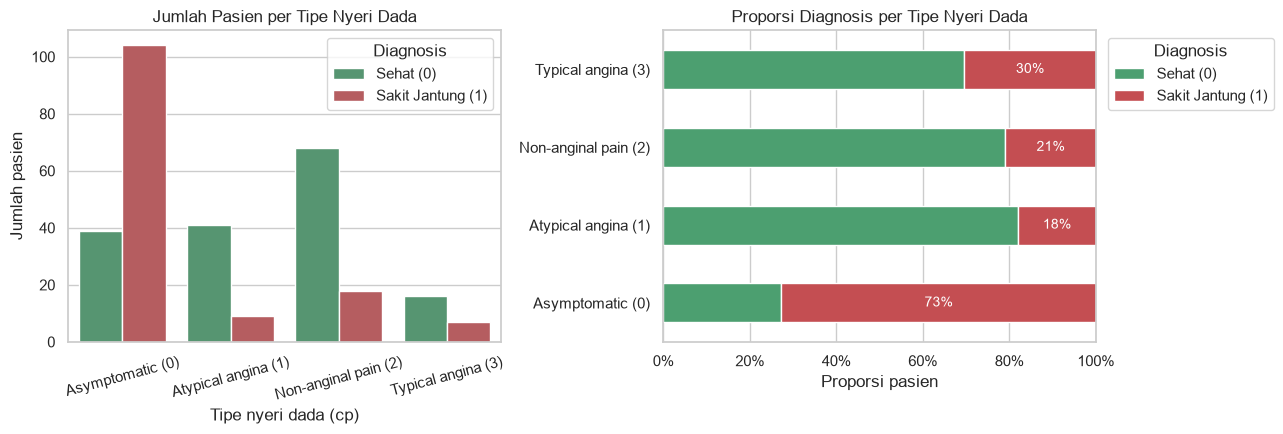

target,0,1,Total
cp,,,
0,39,104,143
1,41,9,50
2,68,18,86
3,16,7,23
Total,164,138,302


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
urutan_cp = list(LABEL_CP.values())
sns.countplot(data=df_eda, x="tipe_nyeri", hue="diagnosis", order=urutan_cp,
              hue_order=urutan, palette=WARNA_TARGET, ax=axes[0])
axes[0].set_title("Jumlah Pasien per Tipe Nyeri Dada")
axes[0].set_xlabel("Tipe nyeri dada (cp)")
axes[0].set_ylabel("Jumlah pasien")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Diagnosis")

proporsi_cp = pd.crosstab(df_eda["tipe_nyeri"], df_eda["diagnosis"], normalize="index")
proporsi_cp = proporsi_cp.loc[urutan_cp, urutan]
proporsi_cp.plot(kind="barh", stacked=True, ax=axes[1],
                 color=[WARNA_TARGET[k] for k in urutan])
for i, nilai in enumerate(proporsi_cp["Sakit Jantung (1)"]):
    axes[1].text(1 - nilai / 2, i, persen_id(nilai), ha="center", va="center",
                 color="white", fontsize=10)
axes[1].set_title("Proporsi Diagnosis per Tipe Nyeri Dada")
axes[1].set_xlabel("Proporsi pasien")
axes[1].set_xlim(0, 1)
format_sumbu_id(axes[1].xaxis, 0, persen=True)
axes[1].set_ylabel("")
axes[1].legend(title="Diagnosis", loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
simpan_grafik(fig, "fase-1-cp-vs-target")
plt.show()

pd.crosstab(df["cp"], df["target"], margins=True, margins_name="Total")

**Temuan:** Tipe nyeri dada membedakan kedua kelas dengan jelas. Sebanyak 73% pasien dengan nyeri dada *asymptomatic* (`cp = 0`, tidak merasakan nyeri dada yang khas) tergolong sakit jantung, dan kelompok ini juga yang paling besar (143 pasien). Pada tipe lainnya, proporsi pasien sakit jantung jauh lebih rendah: 18% (*atypical angina*), 21% (*non-anginal pain*), dan 30% (*typical angina*). Artinya, tidak adanya keluhan nyeri dada yang khas bukan jaminan pasien sehat, sehingga skrining tetap perlu memakai indikator lain. Fitur `cp` kemungkinan besar menjadi prediktor penting. Karena `cp` bersifat nominal (angkanya tidak menunjukkan urutan), fitur ini perlu di-*One-Hot Encoding* pada Fase 2.

#### c. Distribusi fitur numerik utama terhadap `target`

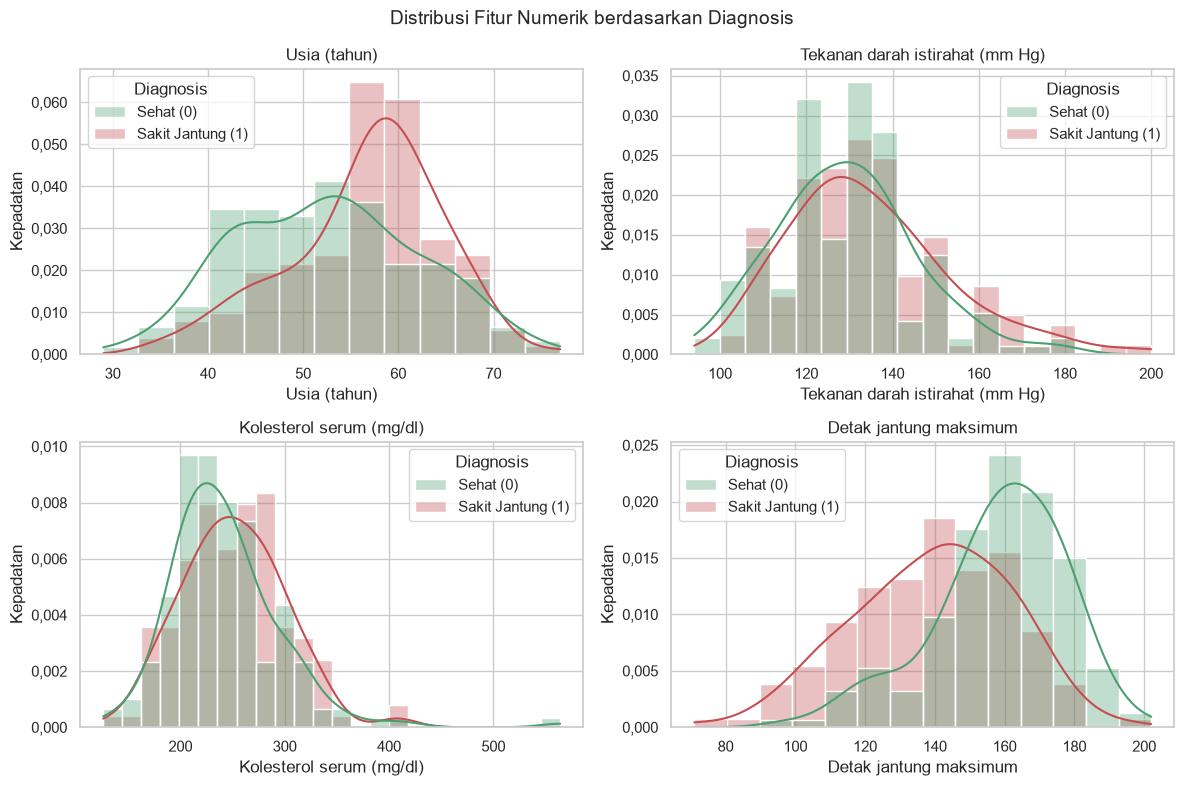

age        trestbps          chol        thalach       
        mean median     mean median   mean median    mean median
target                                                          
0       52.6   52.0    129.2  130.0  242.6  234.5   158.4  161.0
1       56.6   58.0    134.4  130.0  251.1  249.0   139.1  142.0

In [16]:
fitur_numerik = {
    "age": "Usia (tahun)",
    "trestbps": "Tekanan darah istirahat (mm Hg)",
    "chol": "Kolesterol serum (mg/dl)",
    "thalach": "Detak jantung maksimum",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (kolom, label) in zip(axes.flat, fitur_numerik.items()):
    sns.histplot(data=df_eda, x=kolom, hue="diagnosis", hue_order=urutan,
                 palette=WARNA_TARGET, kde=True, stat="density",
                 common_norm=False, alpha=0.35, ax=ax)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Kepadatan")
    format_sumbu_id(ax.yaxis, 3)
    ax.get_legend().set_title("Diagnosis")
fig.suptitle("Distribusi Fitur Numerik berdasarkan Diagnosis", fontsize=14)
fig.tight_layout()
simpan_grafik(fig, "fase-1-numerik-vs-target")
plt.show()

df.groupby("target")[list(fitur_numerik)].agg(["mean", "median"]).round(1)

**Temuan:**

- `thalach` (detak jantung maksimum) paling jelas memisahkan kedua kelas. Median kelas sakit jantung 142, sedangkan kelas sehat 161. Ini sesuai pengetahuan medis: jantung dengan aliran darah terganggu tidak mampu mencapai detak maksimum setinggi jantung sehat saat tes latihan.
- Pasien sakit jantung cenderung lebih tua (median 58 tahun) dibanding pasien sehat (median 52 tahun).
- `trestbps` dan `chol` memiliki distribusi yang hampir tumpang tindih antara kedua kelas. Median `trestbps` sama-sama 130 mm Hg, dan median `chol` hanya berbeda sekitar 15 mg/dl. Pada dataset ini, tekanan darah dan kolesterol secara sendiri-sendiri bukan pembeda yang kuat.
- `chol` memiliki beberapa nilai ekstrem (maksimum 564 mg/dl). Nilai ini masih mungkin terjadi secara medis, jadi tidak dihapus.

#### d. Matriks korelasi antar fitur medis

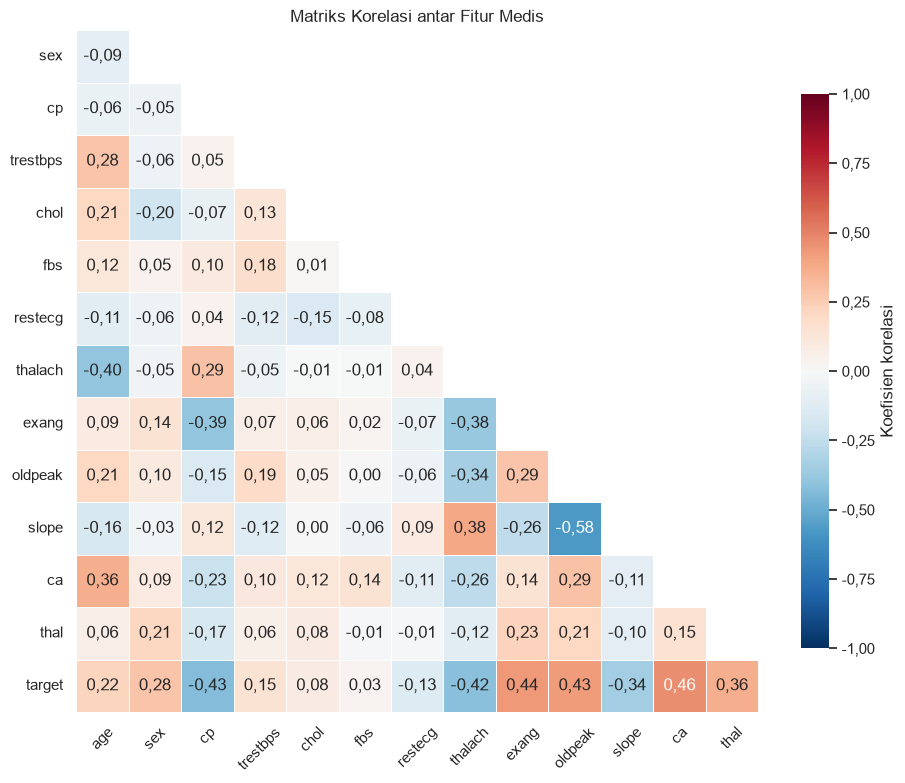

,korelasi_dengan_target
ca,0.46
exang,0.44
cp,-0.43
oldpeak,0.43
thalach,-0.42
thal,0.36
slope,-0.34
sex,0.28
age,0.22
trestbps,0.15


In [17]:
korelasi = df.corr()
fig, ax = plt.subplots(figsize=(11, 9))
# Baris pertama dan kolom terakhir dibuang karena isinya kosong setelah segitiga atas disembunyikan
korelasi_plot = korelasi.iloc[1:, :-1]
mask = np.triu(np.ones_like(korelasi_plot, dtype=bool), k=1)
label_korelasi = korelasi_plot.map(lambda v: angka_id(v, 2))
sns.heatmap(korelasi_plot, mask=mask, annot=label_korelasi, fmt="", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Koefisien korelasi"}, ax=ax)
ax.set_title("Matriks Korelasi antar Fitur Medis")
ax.grid(False)
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
format_sumbu_id(ax.collections[0].colorbar.ax.yaxis, 2)
simpan_grafik(fig, "fase-1-korelasi")
plt.show()

(korelasi["target"].drop("target")
 .sort_values(key=abs, ascending=False)
 .round(2).to_frame("korelasi_dengan_target"))

**Temuan:**

- Fitur dengan korelasi terkuat terhadap `target` adalah `ca` (0,46), `exang` (0,44), `cp` (-0,43), `oldpeak` (0,43), dan `thalach` (-0,42). Arah korelasinya sesuai pengetahuan medis: makin banyak pembuluh darah yang tampak menyempit (`ca`), adanya angina saat olahraga (`exang`), dan depresi ST yang lebih besar (`oldpeak`) berkaitan dengan penyakit jantung, sedangkan detak jantung maksimum yang tinggi berkaitan dengan jantung sehat.
- `chol` (0,08) dan `trestbps` (0,15) memiliki korelasi lemah. Ini berbeda dengan dugaan awal di panduan bahwa kolesterol dan tekanan darah adalah prediktor terkuat. Hal ini akan diuji kembali di Fase 5 melalui analisis faktor risiko dari model.
- Korelasi antar fitur tertinggi adalah `oldpeak` dengan `slope` (-0,58), disusul `age` dengan `thalach` (-0,40). Tidak ada pasangan fitur yang korelasinya sangat tinggi (di atas 0,8), sehingga semua fitur dapat dipertahankan.
- Korelasi Pearson hanya mengukur hubungan linear. Untuk fitur nominal seperti `cp` dan `thal`, angka ini hanya gambaran kasar.

### 1.10 Validasi Klinis Setelah Koreksi Label

Tabel berikut membandingkan rata-rata beberapa indikator klinis antara kedua kelas setelah label dikoreksi di bagian 1.8.

In [18]:
df.groupby("target")[["thalach", "oldpeak", "exang", "ca", "sex", "age"]].mean().round(2)

,thalach,oldpeak,exang,ca,sex,age
target,,,,,,
0,158.38,0.59,0.14,0.27,0.56,52.59
1,139.10,1.59,0.55,1.15,0.83,56.60


Setelah koreksi, pola data sesuai dengan pengetahuan medis. Dibanding pasien sehat, pasien sakit jantung memiliki detak jantung maksimum lebih rendah (139 vs 158), depresi ST lebih tinggi (1,59 vs 0,59), lebih sering mengalami angina saat olahraga (55% vs 14%), lebih banyak pembuluh darah yang tampak menyempit (rata-rata `ca` 1,15 vs 0,27), lebih banyak laki-laki (83% vs 56%), dan usianya sedikit lebih tua (56,6 vs 52,6 tahun).

Konsistensi ini menjadi pemeriksaan tambahan bahwa koreksi label di bagian 1.8 sudah tepat. Seluruh fase berikutnya memakai label yang sudah dikoreksi, sehingga Recall kelas 1 benar-benar mengukur kemampuan model menemukan pasien sakit jantung.

### Pengecekan otomatis: grafik EDA tersimpan
Memastikan keempat grafik Fase 1 tersimpan di `05-output/figures` untuk dipakai di laporan dan slide.

In [19]:
for nama in ["distribusi-target", "cp-vs-target", "numerik-vs-target", "korelasi"]:
    assert (FIG_DIR / f"fase-1-{nama}.png").exists(), nama
assert LABEL_CP[0].startswith("Asymptomatic") and LABEL_CP[3].startswith("Typical")
assert df.groupby("target")["thalach"].mean().is_monotonic_decreasing  # pasien sakit: detak maksimum lebih rendah
import re
for nama, fig in GRAFIK_TERSIMPAN.items():
    teks = [t.get_text() for ax in fig.axes for t in ax.texts + ax.get_xticklabels() + ax.get_yticklabels()]
    salah = [t for t in teks if re.search(r"\d\.\d", t)]
    assert not salah, f"{nama} masih memakai titik desimal: {salah[:3]}"
label_x = [t.get_text() for t in GRAFIK_TERSIMPAN["fase-1-cp-vs-target"].axes[1].get_xticklabels()]
assert label_x and all(re.fullmatch(r"\d+%", t) for t in label_x if t), label_x
print("Pengecekan grafik Fase 1: OK")

Pengecekan grafik Fase 1: OK


## Fase 2: Data Preparation

Fase ini menyiapkan data hasil Fase 1 (`df`, 302 pasien, label sudah dikoreksi) supaya bisa dipakai tiga model di Fase 3. Keputusan di fase ini berasal langsung dari temuan EDA:

| Temuan Fase 1 | Keputusan Fase 2 |
|---|---|
| Kelas cukup seimbang (54:46) | Tidak perlu SMOTE, cukup `stratify=y` saat split |
| `cp`, `restecg`, `slope`, `thal` adalah kategori nominal | One-Hot Encoding |
| Skala fitur numerik sangat berbeda (misalnya `chol` ratusan, `oldpeak` satuan) | StandardScaler, wajib untuk SVM dan KNN |
| `thal` dan `ca` punya missing value | Imputasi modus, dihitung dari data latih saja |

Prinsip utama fase ini adalah mencegah *data leakage*: semua statistik (mean, standard deviation, modus) hanya boleh dihitung dari data latih.

### 2.1 Pemisahan Fitur dan Target

Ke-13 fitur dibagi menjadi empat kelompok, karena setiap kelompok membutuhkan perlakuan yang berbeda:

- **Numerik** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`): angka hasil pengukuran. Skalanya berbeda-beda, jadi perlu disamakan dengan StandardScaler.
- **Nominal** (`cp`, `restecg`, `slope`, `thal`): kode kategori tanpa urutan. Angkanya hanya label, jadi perlu diubah dengan One-Hot Encoding supaya model tidak menganggap kode 3 "lebih besar" dari kode 1.
- **Ordinal** (`ca`): kategori yang urutannya bermakna (jumlah pembuluh darah 0 sampai 3), jadi tetap dipakai sebagai angka.
- **Biner** (`sex`, `fbs`, `exang`): sudah bernilai 0 atau 1, jadi dibiarkan apa adanya.

In [20]:
KOLOM_NUMERIK = ["age", "trestbps", "chol", "thalach", "oldpeak"]
KOLOM_NOMINAL = ["cp", "restecg", "slope", "thal"]
KOLOM_ORDINAL = ["ca"]
KOLOM_BINER = ["sex", "fbs", "exang"]

X = df.drop(columns="target")
y = df["target"]
print(f"X: {X.shape[0]} baris x {X.shape[1]} fitur")
print(f"y: {y.shape[0]} label, {int(y.sum())} sakit dan {int((y == 0).sum())} sehat")

X: 302 baris x 13 fitur
y: 302 label, 138 sakit dan 164 sehat


### 2.2 Train-Test Split

Data dibagi 80:20. Data latih (80%) dipakai model untuk belajar, sedangkan data uji (20%) disimpan dan hanya dipakai sekali di akhir Fase 4 untuk mengukur kemampuan model pada pasien yang belum pernah dilihat.

Rasio 80:20 dipilih (bukan 70:30) karena dataset kecil, sehingga model butuh data latih sebanyak mungkin. Parameter `stratify=y` menjaga proporsi pasien sakit tetap sama di data latih dan data uji, dan `random_state=RANDOM_STATE` membuat pembagiannya selalu sama setiap kali notebook dijalankan.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

ringkasan_split = pd.DataFrame({
    "jumlah_pasien": [len(y), len(y_train), len(y_test)],
    "sakit": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    "proporsi_sakit": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["Keseluruhan", "Data latih", "Data uji"])
ringkasan_split.assign(proporsi_sakit=ringkasan_split["proporsi_sakit"].map(lambda p: persen_id(p, 1)))

,jumlah_pasien,sakit,proporsi_sakit
Keseluruhan,302,138,"45,7%"
Data latih,241,110,"45,6%"
Data uji,61,28,"45,9%"


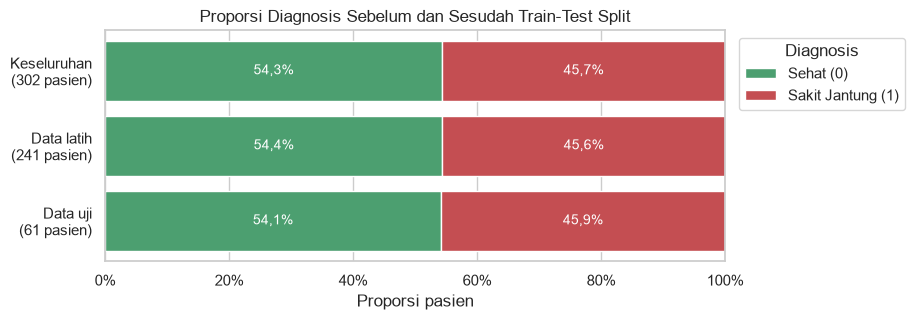

In [22]:
fig, ax = plt.subplots(figsize=(8, 3))
sehat = 1 - ringkasan_split["proporsi_sakit"]
sakit = ringkasan_split["proporsi_sakit"]
label_baris = [f"{nama}\n({n} pasien)" for nama, n in zip(ringkasan_split.index, ringkasan_split["jumlah_pasien"])]
ax.barh(label_baris, sehat, color=WARNA_TARGET["Sehat (0)"], label="Sehat (0)")
ax.barh(label_baris, sakit, left=sehat, color=WARNA_TARGET["Sakit Jantung (1)"], label="Sakit Jantung (1)")
for i, (s, k) in enumerate(zip(sehat, sakit)):
    ax.text(s / 2, i, persen_id(s, 1), ha="center", va="center", color="white", fontsize=10)
    ax.text(s + k / 2, i, persen_id(k, 1), ha="center", va="center", color="white", fontsize=10)
ax.set_xlim(0, 1)
format_sumbu_id(ax.xaxis, 0, persen=True)
ax.invert_yaxis()
ax.set_xlabel("Proporsi pasien")
ax.set_title("Proporsi Diagnosis Sebelum dan Sesudah Train-Test Split")
ax.legend(title="Diagnosis", loc="upper left", bbox_to_anchor=(1.01, 1))
simpan_grafik(fig, "fase-2-split")
plt.show()

**Temuan:** Data latih berisi 241 pasien (110 sakit) dan data uji berisi 61 pasien (28 sakit). Berkat `stratify=y`, proporsi pasien sakit hampir sama di ketiga kelompok, yaitu sekitar 45,6% sampai 45,9%. Dengan begitu, data uji mewakili komposisi pasien secara keseluruhan.

### Pengecekan otomatis: pembagian data
Memastikan semua kolom fitur sudah masuk kelompoknya, label hasil koreksi Fase 1 terbawa, dan pembagian 80:20 menjaga proporsi kelas.

In [23]:
assert sorted(KOLOM_NUMERIK + KOLOM_NOMINAL + KOLOM_ORDINAL + KOLOM_BINER) == sorted(X.columns)
assert X.shape == (302, 13) and "target" not in X.columns
assert y.sum() == 138  # label Fase 1 tetap terkoreksi
assert X_train.shape == (241, 13) and X_test.shape == (61, 13)
assert y_train.sum() == 110 and y_test.sum() == 28
assert set(X_train.index).isdisjoint(X_test.index)
assert (FIG_DIR / "fase-2-split.png").exists()
print("Pengecekan pembagian data: OK")

Pengecekan pembagian data: OK
